# Uczenie głębokie — Zajęcia 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_5.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_5/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Sieć neuronowa — warstwa ukryta i trening w paczkach

Na poprzednich zajęciach zbudowaliśmy jeden neuron i okazało się, że to po
prostu regresja logistyczna. Na koniec padło też zastrzeżenie: neuron liczy
ważoną sumę, więc umie powiedzieć tylko „im więcej X, tym większe (albo
mniejsze) ryzyko" — zawsze w tę samą stronę. Dziś pokażemy na prawdziwych
danych, że to za mało, i zrobimy to, co zapowiedzieliśmy: ułożymy neurony
w **warstwy**. Tak powstaje **sieć neuronowa** — pierwsza prawdziwa w tym
semestrze.

Przy okazji nauczymy się trenować tak, jak trenuje się duże sieci: nie na
całym zbiorze naraz, tylko w **paczkach**, i z oczami utkwionymi w dwóch
krzywych uczenia zamiast jednej.

Po dzisiejszych zajęciach będziesz w stanie:

- wskazać na danych zależność, której jeden neuron nie zapisze,
- wyjaśnić, czym jest warstwa ukryta i funkcja aktywacji ReLU — i dlaczego
  bez aktywacji kolejne warstwy nic nie dają,
- zbudować sieć gęstą w PyTorch i policzyć jej parametry,
- trenować sieć w paczkach (`DataLoader`) i odróżnić krok od epoki,
- narysować krzywą treningową i walidacyjną i rozpoznać na nich przeuczenie.

> ℹ️ **Godzinę temu na Data Science w Pythonie**
>
> Budowaliśmy cechy. Dla MeritoBanku wyszło, że ważniejsza od kwoty kredytu
> i dochodu jest relacja między nimi — **obciążenie ratą** — i że ryzyko
> nie rośnie z nim równo, tylko skacze od ok. 30% dochodu. W zadaniu
> sprawdzisz, co daje więcej: większy model czy lepsza cecha.


## Plan na dziś

| Blok | Czas |
|---|---|
| Czego jeden neuron nie umie — na prawdziwych danych | 5 min |
| Warstwa ukryta i ReLU | 10 min |
| Sieć gęsta w PyTorch | 7 min |
| Trening w paczkach — krok i epoka | 10 min |
| Sieć kontra neuron | 5 min |
| Krzywa walidacyjna i przeuczenie | 5 min |
| Ściągawka | 3 min |
| **Zadanie 5** | **45 min** |


## Czego jeden neuron nie umie

### Dane — tym razem trzy zbiory

Znowu siłownia i te same pięć cech. Nowość: oprócz zbioru treningowego
i testowego wydzielamy **zbiór walidacyjny** — 20% danych treningowych, na
których będziemy podglądać sieć **w trakcie** treningu. Test zostaje nietknięty
do samego końca, jak na zajęciach 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/silownia_czyste.csv"
df = pd.read_csv(URL)

cechy = ["wiek", "oplata_mies", "staz_mies", "wizyty_mies", "zgloszenia"]
X = df[cechy]
y = df["zrezygnowal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
print("trening:", len(X_tr), " walidacja:", len(X_val), " test:", len(X_test))

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

trening: 949  walidacja: 238  test: 297


Skaler uczy się **tylko** na zbiorze treningowym — walidacja i test są tylko
przekształcane. To ta sama zasada co przy wycieku danych z zajęć 3.

### Zapaleńcy się wypalają

Na końcu poprzednich zajęć rzuciliśmy hipotezę: a gdyby klienci z bardzo dużą
liczbą wizyt też częściej rezygnowali? Sprawdźmy:

In [2]:
przedzialy = pd.cut(df["wizyty_mies"], bins=[0, 2, 4, 6, 8, 10, 15, 25])
df.groupby(przedzialy, observed=True)["zrezygnowal"].agg(["count", "mean"]).round(2)

,count,mean
wizyty_mies,,
"(0, 2]",104,0.54
"(2, 4]",341,0.38
"(4, 6]",325,0.23
"(6, 8]",274,0.11
"(8, 10]",197,0.10
"(10, 15]",196,0.16
"(15, 25]",47,0.17


Odsetek rezygnacji spada z każdą wizytą — do ok. 10% przy 6–10 wizytach
w miesiącu. Ale potem **przestaje spadać**, a nawet lekko rośnie: wśród
klientów, którzy przychodzą ponad 10 razy w miesiącu, odchodzi 16–17%.

Jeden neuron tego nie zapisze. Ma dla wizyt jedną wagę — ujemną — więc
zawsze mówi „więcej wizyt, mniejsze ryzyko", aż do zera. Dla klienta
z 20 wizytami da ryzyko bliskie 0%, choć w danych jest 17%. Potrzebujemy
modelu, który umie **zgiąć** krzywą.


## Warstwa ukryta

### Kilka neuronów zamiast jednego

Pomysł jest prosty: zamiast od razu liczyć wynik, najpierw puszczamy cechy
przez **kilka neuronów naraz**. Każdy z nich liczy własną ważoną sumę
z własnymi wagami — każdy może więc „zauważyć" coś innego. Ich wyniki trafiają
do ostatniego neuronu, który liczy z nich prawdopodobieństwo.

![Schemat sieci 5 → 8 → 1](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/obrazki/zajecia_5_siec.png)

- **Warstwa wejściowa** to po prostu cechy — tu 5 liczb. Nic w niej nie
  liczymy.
- **Warstwa ukryta** to 8 neuronów. „Ukryta", bo jej wyników nikt nie ogląda —
  to obliczenia pośrednie. Każdy neuron jest połączony z **każdą** cechą.
- **Warstwa wyjściowa** to jeden neuron z sigmoidą — ten sam, który znasz
  z zajęć 4, tyle że jego wejściami są wyniki warstwy ukrytej, a nie cechy.

Taka sieć, w której każdy neuron jednej warstwy jest połączony z każdym
neuronem następnej, to **sieć gęsta** (*dense*, *fully connected*), zwana też
**perceptronem wielowarstwowym** (*multilayer perceptron*, MLP). Zapisujemy ją
skrótem **5 → 8 → 1**. Kiedy warstw ukrytych jest kilka, mówimy o sieci
**głębokiej** — stąd nazwa naszego przedmiotu.

### ReLU — po co aktywacja w środku

W neuronach warstwy ukrytej nie używa się zwykle sigmoidy, tylko dużo
prostszej funkcji **ReLU** (*rectified linear unit*):

> ReLU(z) = max(0, z) — liczby ujemne zamienia na zero, dodatnie zostawia bez
> zmian.

Brzmi niewinnie, ale to ona robi całą robotę. Spójrz, jak dwa neurony z ReLU
potrafią razem zgiąć krzywą:

![ReLU i jak dwa neurony ukryte zginają krzywą](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/obrazki/zajecia_5_relu.png)

- Po lewej sama ReLU: płasko, a od zera w górę.
- W środku dwa neurony ukryte, każdy z inną wagą i biasem. Pierwszy „odpala"
  przy **małej** liczbie wizyt (im mniej, tym mocniej), drugi — dopiero przy
  **bardzo dużej**. Pomiędzy oba milczą.
- Po prawej neuron wyjściowy dodaje je z wagami i przepuszcza przez sigmoidę.
  Wychodzi krzywa, która spada, leży płasko i znowu rośnie — dokładnie kształt
  z naszej tabeli, którego jeden neuron nie umiał.

Więcej neuronów ukrytych to więcej „załamań" — z odpowiednio wielu kawałków da
się złożyć dowolny kształt. Wagi i biasy, które o tym decydują, sieć znajduje
**sama** podczas treningu, tym samym spadkiem gradientu co na zajęciach 4.

> ⚠️ **Bez aktywacji warstwy nic nie dają**
>
> Gdyby usunąć ReLU, warstwa ukryta liczyłaby ważone sumy, a warstwa
> wyjściowa — ważoną sumę ważonych sum. A ważona suma ważonych sum to…
> znowu ważona suma, tylko z innymi wagami. Sieć 5 → 8 → 1 bez aktywacji
> potrafi dokładnie tyle samo co jeden neuron. Funkcja aktywacji między
> warstwami to warunek konieczny, żeby więcej warstw dawało więcej
> możliwości.


## Sieć gęsta w PyTorch

### Tensory

Jak na zajęciach 4 zamieniamy dane na tensory — tym razem trzy zestawy:

In [3]:
import torch
from torch import nn

X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)

y_tr_t = torch.tensor(y_tr.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)

Etykiet testowych nie zamieniamy — do metryk ze scikit-learn wystarczy zwykłe
`y_test`.

### Model

Sieć 5 → 8 → 1 to cztery kroki w `nn.Sequential`:

In [4]:
torch.manual_seed(42)

siec = nn.Sequential(
    nn.Linear(5, 8),   # warstwa ukryta: 8 neuronów, każdy widzi 5 cech
    nn.ReLU(),         # aktywacja warstwy ukrytej
    nn.Linear(8, 1),   # warstwa wyjściowa: 1 neuron, widzi 8 wyników warstwy ukrytej
    nn.Sigmoid(),      # prawdopodobieństwo 0–1
)
siec

Sequential(
  (0): Linear(in_features=5, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
  (3): Sigmoid()
)

Porównaj z neuronem z zajęć 4 — `nn.Sequential(nn.Linear(5, 1), nn.Sigmoid())`.
Doszły dwie linijki w środku. Zasada jest jedna: **liczba wyjść jednej warstwy
`Linear` = liczba wejść następnej** (tu 8 i 8).

### Ile sieć ma parametrów

Parametry to wszystkie wagi i biasy, których sieć się uczy:

In [5]:
for nazwa, p in siec.named_parameters():
    print(nazwa, tuple(p.shape))

print("razem:", sum(p.numel() for p in siec.parameters()))

0.weight (8, 5)
0.bias (8,)
2.weight (1, 8)
2.bias (1,)
razem: 57


Policzmy na palcach:

| Warstwa | Wagi | Biasy | Razem |
|---|---|---|---|
| `Linear(5, 8)` | 5 × 8 = 40 (każdy z 8 neuronów ma wagę dla każdej z 5 cech) | 8 | 48 |
| `Linear(8, 1)` | 8 × 1 = 8 | 1 | 9 |
| **sieć** | | | **57** |

Jeden neuron miał 6 parametrów, sieć ma 57. `ReLU` i `Sigmoid` nie mają
żadnych — to stałe funkcje. Ogólnie: warstwa `Linear(a, b)` ma
**a × b + b** parametrów.


## Trening w paczkach

### Krok i epoka

Na zajęciach 4 każdy krok spadku gradientu liczyliśmy na **wszystkich**
klientach naraz. Przy tysiącu klientów to działa. Przy milionie zdjęć — nie:
nie zmieszczą się w pamięci karty graficznej, a jeden krok trwałby wieki.

Dlatego sieci trenuje się w **paczkach** (*mini-batch*): bierzemy 32 losowych
klientów, liczymy stratę i gradient tylko na nich, robimy krok — i bierzemy
następnych 32. Gradient z 32 przykładów jest trochę „zaszumiony", ale za to
kroków jest dużo więcej i są szybkie. W praktyce sieć uczy się tak szybciej.

- **krok** — jedna paczka: przewidywania, strata, gradient, poprawka wag,
- **epoka** — jedno przejście przez cały zbiór treningowy, czyli tyle kroków,
  ile jest paczek.

Paczki kroi za nas `DataLoader`:

In [6]:
from torch.utils.data import TensorDataset, DataLoader

paczki = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

xb, yb = next(iter(paczki))
print("jedna paczka:", tuple(xb.shape), tuple(yb.shape))
print("paczek w epoce:", len(paczki))

jedna paczka: (32, 5) (32, 1)
paczek w epoce: 30


- `TensorDataset(X, y)` skleja cechy z etykietami, żeby paczka zawsze miała
  pasujące do siebie wiersze.
- `batch_size=32` — wielkość paczki. 32 to bardzo typowa wartość.
- `shuffle=True` — w każdej epoce paczki są losowane od nowa, żeby sieć nie
  uczyła się w kółko tej samej kolejności.
- 949 klientów / 32 = 29.7, więc w epoce jest 30 paczek (ostatnia mniejsza).

### Pętla treningowa w paczkach

Pięć kroków z zajęć 4 zostaje bez zmian. Dochodzi tylko druga, wewnętrzna
pętla — po paczkach — i sprawdzian na walidacji po każdej epoce:

In [7]:
funkcja_straty = nn.BCELoss()
optymalizator = torch.optim.SGD(siec.parameters(), lr=0.1)

historia_tr, historia_val = [], []
for epoka in range(50):
    suma = 0
    for xb, yb in paczki:                          # jedna paczka = jeden krok
        optymalizator.zero_grad()
        strata = funkcja_straty(siec(xb), yb)
        strata.backward()
        optymalizator.step()
        suma += strata.item()
    historia_tr.append(suma / len(paczki))         # średnia strata w epoce

    with torch.no_grad():                          # po epoce: sprawdzian na walidacji
        historia_val.append(funkcja_straty(siec(X_val_t), y_val_t).item())

print("strata treningowa:", round(historia_tr[-1], 3), " walidacyjna:", round(historia_val[-1], 3))

strata treningowa: 0.425  walidacyjna: 0.43


50 epok × 30 paczek = 1500 kroków. Na zajęciach 4 przez 200 epok zrobiliśmy
200 kroków.

Text(0, 0.5, 'strata (BCE)')

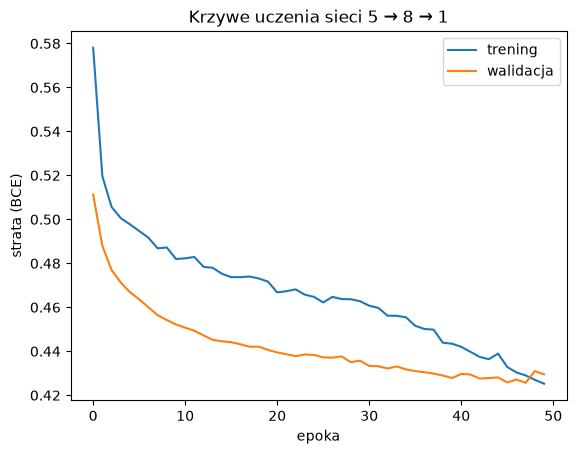

In [8]:
plt.plot(historia_tr, label="trening")
plt.plot(historia_val, label="walidacja")
plt.legend()
plt.title("Krzywe uczenia sieci 5 → 8 → 1")
plt.xlabel("epoka")
plt.ylabel("strata (BCE)")

Dwie krzywe, dwie informacje:

- **treningowa** — jak dobrze sieć radzi sobie z danymi, na których się uczy,
- **walidacyjna** — jak dobrze radzi sobie z danymi, których **nie widziała**.
  To jest ta, która nas naprawdę obchodzi.

Obie spadają — sieć nauczyła się czegoś, co działa też na nowych klientach.
Walidacyjna leży nawet trochę niżej niż treningowa. To nic dziwnego: strata
treningowa to średnia z całej epoki, w trakcie której sieć dopiero się
poprawiała, a walidacja to tylko 238 osób, akurat trochę łatwiejszych.
Ważne, że obie idą w dół razem.

> 📝 **Dlaczego krzywa treningowa skacze?**
>
> Każda epoka to inne losowanie paczek, a każdy krok — gradient tylko z 32
> osób. Strata treningowa nie spada więc idealnie gładko, jak na zajęciach 4.
> To normalne i nie ma się czym martwić, dopóki ogólny kierunek jest w dół.

### Pętla w funkcji

Ta sama pętla przyda się nam jeszcze kilka razy, więc zamykamy ją w funkcji.
Dostaje model i dane, zwraca obie historie:

In [9]:
def trenuj(model, X_tr_t, y_tr_t, X_val_t, y_val_t, epoki=50, lr=0.1):
    paczki = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)
    funkcja_straty = nn.BCELoss()
    optymalizator = torch.optim.SGD(model.parameters(), lr=lr)

    historia_tr, historia_val = [], []
    for epoka in range(epoki):
        suma = 0
        for xb, yb in paczki:
            optymalizator.zero_grad()
            strata = funkcja_straty(model(xb), yb)
            strata.backward()
            optymalizator.step()
            suma += strata.item()
        historia_tr.append(suma / len(paczki))
        with torch.no_grad():
            historia_val.append(funkcja_straty(model(X_val_t), y_val_t).item())
    return historia_tr, historia_val

## Sieć kontra neuron

### Wyniki na teście

Trenujemy jeden neuron dokładnie tak samo — te same paczki, ten sam
współczynnik uczenia, te same 50 epok:

In [10]:
torch.manual_seed(42)
neuron = nn.Sequential(nn.Linear(5, 1), nn.Sigmoid())
historia_neuron = trenuj(neuron, X_tr_t, y_tr_t, X_val_t, y_val_t)

I porównujemy oba modele na zbiorze testowym. Krótka funkcja liczy stratę
logarytmiczną (z zajęć 4) i F1 (z zajęć 2):

In [11]:
from sklearn.metrics import log_loss, f1_score

def ocen(model, X_t, y):
    with torch.no_grad():
        p = model(X_t).numpy().ravel()
    return round(log_loss(y, p), 3), round(f1_score(y, (p > 0.5).astype(int)), 3)

print("jeden neuron   strata, F1:", ocen(neuron, X_test_t, y_test))
print("sieć 5 → 8 → 1 strata, F1:", ocen(siec, X_test_t, y_test))

jeden neuron   strata, F1: (0.463, 0.485)
sieć 5 → 8 → 1 strata, F1: (0.42, 0.632)


Sieć wygrywa wyraźnie — i na stracie, i na F1. To pierwsze w tym semestrze
porównanie, w którym coś pokonało regresję logistyczną.

### Co sieć zauważyła

Zobaczmy dlaczego. Weźmy „typowego klienta" — medianę każdej cechy — i
zmieniajmy mu tylko liczbę wizyt od 0.5 do 20. Dla każdej wartości pytamy oba
modele o ryzyko rezygnacji:

Text(0, 0.5, 'prawdopodobieństwo rezygnacji')

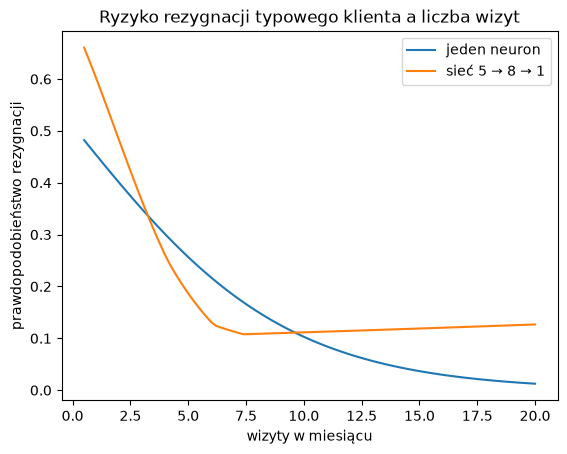

In [12]:
wizyty = np.linspace(0.5, 20, 100)
typowy = pd.DataFrame([X_tr.median()] * len(wizyty))
typowy["wizyty_mies"] = wizyty
typowy_t = torch.tensor(scaler.transform(typowy), dtype=torch.float32)

with torch.no_grad():
    p_neuron = neuron(typowy_t).numpy().ravel()
    p_siec = siec(typowy_t).numpy().ravel()

plt.plot(wizyty, p_neuron, label="jeden neuron")
plt.plot(wizyty, p_siec, label="sieć 5 → 8 → 1")
plt.legend()
plt.title("Ryzyko rezygnacji typowego klienta a liczba wizyt")
plt.xlabel("wizyty w miesiącu")
plt.ylabel("prawdopodobieństwo rezygnacji")

Neuron rysuje swoją jedyną możliwą krzywą — gładki kawałek litery S, który
schodzi do zera. Sieć nauczyła się, że powyżej ok. 7 wizyt ryzyko **przestaje
spadać**, a potem nawet lekko rośnie — tak jak w tabeli z początku zajęć.
Nikt jej tego nie powiedział — znalazła to w danych sama, dobierając wagi
8 neuronów ukrytych.

> 📝 **Sieć sama buduje cechy**
>
> Godzinę temu na DS w Pythonie budowałeś cechy ręcznie — flagę „nowy
> klient", koszt wizyty. Neurony warstwy ukrytej robią coś podobnego
> automatycznie: każdy uczy się jakiejś pośredniej cechy, z której neuron
> wyjściowy liczy wynik. Dlatego sieci tak dobrze radzą sobie z obrazami
> i tekstem, gdzie ręcznie cech zbudować się nie da. Czy to znaczy, że
> feature engineering nie jest już potrzebny? Sprawdzisz w zadaniu.


## Krzywa walidacyjna i przeuczenie

Skoro 8 neuronów pomogło, to może 64 — i to w dwóch warstwach — pomogą
jeszcze bardziej? Zbudujmy naszą pierwszą sieć **głęboką**, 5 → 64 → 64 → 1,
i potrenujmy ją dłużej:

In [13]:
torch.manual_seed(42)
duza = nn.Sequential(
    nn.Linear(5, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1), nn.Sigmoid(),
)
print("parametrów:", sum(p.numel() for p in duza.parameters()))

historia_tr, historia_val = trenuj(duza, X_tr_t, y_tr_t, X_val_t, y_val_t, epoki=300)
print("najniższa strata walidacyjna w epoce:", np.argmin(historia_val))
print("duża sieć      strata, F1:", ocen(duza, X_test_t, y_test))

parametrów: 4609


najniższa strata walidacyjna w epoce: 8
duża sieć      strata, F1: (0.621, 0.535)


Text(0, 0.5, 'strata (BCE)')

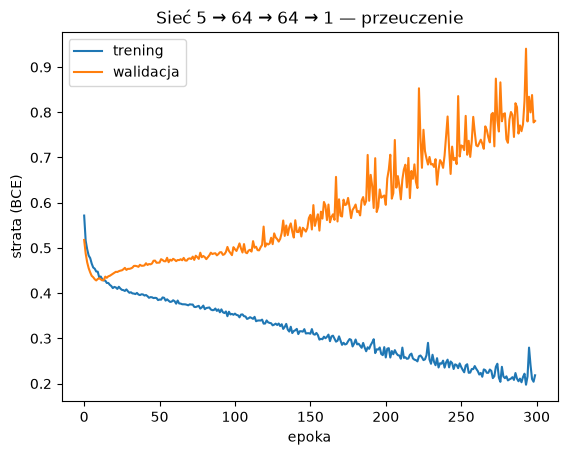

In [14]:
plt.plot(historia_tr, label="trening")
plt.plot(historia_val, label="walidacja")
plt.legend()
plt.title("Sieć 5 → 64 → 64 → 1 — przeuczenie")
plt.xlabel("epoka")
plt.ylabel("strata (BCE)")

To jest najważniejszy wykres dzisiejszych zajęć. Przez pierwszych kilka epok
obie krzywe spadają razem. Potem się **rozjeżdżają**: strata treningowa leci
w dół, a walidacyjna zawraca i rośnie. Sieć z ponad czterema tysiącami
parametrów i tylko 949 klientami do nauki zaczęła się uczyć **na pamięć** —
łącznie z szumem, czyli klientami, którzy odeszli bez widocznego powodu.
Na teście ma stratę gorszą niż mała sieć, a nawet gorszą niż jeden neuron.

To samo **przeuczenie**, które na zajęciach 2 widziałeś przy głębokim
drzewie, tylko teraz widać je epoka po epoce. I od razu widać najprostsze
lekarstwo: przerwać trening tam, gdzie krzywa walidacyjna była najniżej.
Do tego i do innych sposobów — regularyzacji — wrócimy na następnych
zajęciach.

> 💡 **Jak czytać dwie krzywe**
>
> | Co widzisz | Co to znaczy | Co zrobić |
> |---|---|---|
> | obie spadają i się wypłaszczają | dobrze | nic, może dłużej trenować |
> | obie wysoko i płasko | niedouczenie — model za słaby | większa sieć, lepsze cechy |
> | treningowa spada, walidacyjna rośnie | przeuczenie | mniejsza sieć, krótszy trening, regularyzacja |


## Ściągawka

| Chcę… | Kod |
|---|---|
| wydzielić zbiór walidacyjny | `train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)` |
| sieć z jedną warstwą ukrytą | `nn.Sequential(nn.Linear(5, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())` |
| sieć z dwiema warstwami ukrytymi | `nn.Sequential(nn.Linear(5, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1), nn.Sigmoid())` |
| liczba parametrów | `sum(p.numel() for p in model.parameters())` |
| parametry warstwy `Linear(a, b)` | a × b wag + b biasów |
| kształty parametrów | `for nazwa, p in model.named_parameters(): print(nazwa, p.shape)` |
| paczki danych | `DataLoader(TensorDataset(X_t, y_t), batch_size=32, shuffle=True)` |
| liczba paczek w epoce | `len(paczki)` |
| pętla w paczkach | `for epoka in ...:` → `for xb, yb in paczki:` → 5 kroków z zajęć 4 |
| strata walidacyjna po epoce | `with torch.no_grad(): funkcja_straty(model(X_val_t), y_val_t).item()` |
| trening jedną linijką | `historia_tr, historia_val = trenuj(model, X_tr_t, y_tr_t, X_val_t, y_val_t)` |
| ocena na teście | `ocen(model, X_test_t, y_test)` → (strata, F1) |
| epoka z najniższą stratą walidacyjną | `np.argmin(historia_val)` |

## Zadanie 5

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_5/#zadanie-5-wiekszy-model-czy-lepsza-cecha-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.